# BOSTMC 外部验证 — 真正独立数据集

## 为什么 BOSTMC 是完美的外部验证
| | tmQM (训练) | BOSTMC (验证) |
|------|------|------|
| CSD 码重叠 | — | **0%** (完全独立) |
| DFT 泛函 | TPSSh-D3BJ | **PBE0/def2-TZVP** |
| 来源 | CSD 筛选 | CSD 另选 |
| 配合物数 | 108k | 3,277 (hs) |

## 策略
BOSTMC 无 SMILES，用 XYZ 坐标 + 距离边建图 → XYZ GNN 推理

```
XYZ坐标 → 原子配对(covalent radii) → 距离RBF边 → XYZ GNN → 预测值 vs PBE0真值
```


In [1]:
import numpy as np, pandas as pd, torch, torch.nn as nn, os, sys, gzip, tarfile
import warnings; warnings.filterwarnings('ignore')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
torch.backends.cuda.matmul.allow_tf32 = True

from sklearn.metrics import r2_score, mean_absolute_error
from scipy.stats import pearsonr
from tqdm import tqdm

# ===== 加载 BOSTMC 数据 =====
df_bo = pd.read_csv('BOSTMC/manyDFA/properties/manyDFA-hs.csv')
print(f'BOSTMC high-spin: {len(df_bo):,} complexes')

# PBE0 作为参考泛函 (最接近我们的TPSSh训练数据)
pbe0_cols = {
    'gap': 'pbe0 alpha HOMO-LUMO gap (a.u.)',
    'homo': 'pbe0 alpha HOMO (a.u.)',
    'lumo': 'pbe0 alpha LUMO (a.u.)',
    'dipole': 'pbe0 dipole magnitude at COM (debye)',  # 标量, 不是向量
    'E_elec': 'pbe0 electronic energy (a.u.)',
    'metal_charge': 'pbe0 metal lowdin charge',
}
targets_ext = ['gap', 'homo', 'lumo', 'dipole', 'E_elec', 'metal_charge']

# 过滤: 保留 PBE0 收敛且有有效数值的行
df_clean = df_bo[df_bo['pbe0 success'].notna()].copy()
for prop in targets_ext:
    col = pbe0_cols[prop]
    # 强制转为数值, 无法转换的变为 NaN
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')
# 只保留所有6个目标都有值的行
df_clean = df_clean.dropna(subset=[pbe0_cols[p] for p in targets_ext])
df_clean = df_clean.reset_index(drop=True)
print(f'Clean PBE0 data: {len(df_clean):,} complexes (from {len(df_bo):,} total)')
print(f'Targets: {targets_ext}')
# Show sample refcodes for debugging
print(f'Sample refcodes: {df_clean["refcode"].head(5).tolist()}')



Device: cuda


BOSTMC high-spin: 3,277 complexes
Clean PBE0 data: 3,277 complexes (from 3,277 total)
Targets: ['gap', 'homo', 'lumo', 'dipole', 'E_elec', 'metal_charge']
Sample refcodes: ['HOLMIE_comp_0', 'BELGOO10_comp_0', 'BIGNOU01_comp_0', 'ZEZMUM_comp_0', 'HUPKOT_comp_0']


In [2]:
# ===== 从 XYZ 文件建图 =====
# BOSTMC XYZ 文件在 tar 包中, 服务器上先解压
# tar -xzf BOSTMC.tar.gz -C BOSTMC/ --wildcards '*.xyz'  # 服务器上执行

import tarfile, io

# 原子半径 (covalent, Angstrom)
COVALENT_RADII = {
    1:0.31, 5:0.84, 6:0.76, 7:0.71, 8:0.66, 9:0.57, 14:1.11, 15:1.07, 16:1.05,
    17:1.02, 20:1.76, 21:1.70, 22:1.60, 23:1.53, 24:1.39, 25:1.39, 26:1.32,
    27:1.26, 28:1.24, 29:1.32, 30:1.22, 35:1.20, 42:1.54, 44:1.46, 45:1.42,
    46:1.39, 47:1.45, 48:1.44, 53:1.39, 72:1.75, 73:1.70, 74:1.62, 75:1.51,
    76:1.44, 77:1.41, 78:1.36, 79:1.36, 80:1.32,
}
ATOM_TO_Z = {'H':1,'B':5,'C':6,'N':7,'O':8,'F':9,'Si':14,'P':15,'S':16,'Cl':17,
    'Ca':20,'Sc':21,'Ti':22,'V':23,'Cr':24,'Mn':25,'Fe':26,'Co':27,'Ni':28,
    'Cu':29,'Zn':30,'Br':35,'Mo':42,'Ru':44,'Rh':45,'Pd':46,'Ag':47,'Cd':48,
    'I':53,'Hf':72,'Ta':73,'W':74,'Re':75,'Os':76,'Ir':77,'Pt':78,'Au':79,'Hg':80}

# 元素周期表信息
PERIOD_GROUP = {1:(1,1),5:(2,13),6:(2,14),7:(2,15),8:(2,16),9:(2,17),14:(3,14),
    15:(3,15),16:(3,16),17:(3,17),20:(4,2),21:(4,3),22:(4,4),23:(4,5),24:(4,6),
    25:(4,7),26:(4,8),27:(4,9),28:(4,10),29:(4,11),30:(4,12),35:(4,17),42:(5,6),
    44:(5,8),45:(5,9),46:(5,10),47:(5,11),48:(5,12),53:(5,17),72:(6,4),73:(6,5),
    74:(6,6),75:(6,7),76:(6,8),77:(6,9),78:(6,10),79:(6,11),80:(6,12)}

rbf_c = np.linspace(1.0, 5.0, 16)
rbf_sigma = 0.2

def xyz_to_graph(xyz_content, max_neighbors=12):
    '''从 XYZ 内容构建距离图'''
    lines = xyz_content.strip().split(chr(10))
    n_atoms = int(lines[0].strip())
    atoms = []
    coords = []
    for line in lines[2:2+n_atoms]:
        parts = line.split()
        sym = parts[0]
        z = ATOM_TO_Z.get(sym, 0)
        atoms.append({'sym': sym, 'z': z})
        coords.append([float(x) for x in parts[1:4]])
    coords = np.array(coords, dtype=np.float32)

    # 距离矩阵
    diff = coords[np.newaxis,:,:] - coords[:,np.newaxis,:]
    dist = np.sqrt((diff**2).sum(axis=2))

    # 构建边: covalent radii cutoff
    src, dst, edge_feats = [], [], []
    for i in range(n_atoms):
        for j in range(i+1, n_atoms):
            ri = COVALENT_RADII.get(atoms[i]['z'], 0.7)
            rj = COVALENT_RADII.get(atoms[j]['z'], 0.7)
            cutoff = (ri + rj) * 1.3  # 30% tolerance
            d = dist[i,j]
            if d < cutoff and d < 5.0:
                src.extend([i,j]); dst.extend([j,i])
                feat = [0.0]*4  # bond type (all unknown)
                feat.extend([0.0, 1.0 if (atoms[i]['z']>=21)!=(atoms[j]['z']>=21) else 0.0])
                for mu in rbf_c: feat.append(np.exp(-(d-mu)**2/rbf_sigma))
                feat.append(0.0)  # BO unknown
                edge_feats.extend([feat, feat])

    # 节点特征 (11-dim, 匹配 XYZ GNN)
    xf = []
    for a in atoms:
        z = a['z']; pg = PERIOD_GROUP.get(z, (0,0))
        xf.append([z, 0, 0, pg[0], pg[1], 0, 0, int(z>=21), 0, 0.0, 0.0])
    x = torch.tensor(xf, dtype=torch.float32)
    ei = torch.tensor([src,dst], dtype=torch.long) if src else torch.zeros(2,0,dtype=torch.long)
    ea = torch.tensor(edge_feats, dtype=torch.float32) if edge_feats else torch.zeros(0,23)
    return {'x':x, 'edge_index':ei, 'edge_attr':ea, 'num_nodes':n_atoms}

# SMILES graph builder (for SMILES GAT inference)
ELEMENT_DATA = {1:(1,1),5:(2,13),6:(2,14),7:(2,15),8:(2,16),9:(2,17),14:(3,14),15:(3,15),16:(3,16),17:(3,17),20:(4,2),21:(4,3),22:(4,4),23:(4,5),24:(4,6),25:(4,7),26:(4,8),27:(4,9),28:(4,10),29:(4,11),30:(4,12),35:(4,17),42:(5,6),44:(5,8),45:(5,9),46:(5,10),47:(5,11),48:(5,12),53:(5,17),72:(6,4),73:(6,5),74:(6,6),75:(6,7),76:(6,8),77:(6,9),78:(6,10),79:(6,11),80:(6,12)}
BOND_TYPES_SM = [1,2,3,12]; B2I_SM = {b:i for i,b in enumerate(BOND_TYPES_SM)}; N_BT_SM = len(BOND_TYPES_SM)

def smiles_to_graph(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None: return None
    x = torch.tensor([[a.GetAtomicNum(), a.GetDegree(), a.GetFormalCharge(),
          ELEMENT_DATA.get(a.GetAtomicNum(),(0,0))[0], ELEMENT_DATA.get(a.GetAtomicNum(),(0,0))[1],
          int(a.GetIsAromatic()), a.GetTotalNumHs(), int(a.GetAtomicNum()>=21)]
          for a in mol.GetAtoms()], dtype=torch.float32)
    N = x.size(0); src, dst, battr = [], [], []
    for bond in mol.GetBonds():
        i,j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bt = int(bond.GetBondType())
        za,zb = mol.GetAtomWithIdx(i).GetAtomicNum(), mol.GetAtomWithIdx(j).GetAtomicNum()
        is_ml = float((za>=21)!=(zb>=21)); is_ring = float(bond.IsInRing())
        src.extend([i,j]); dst.extend([j,i])
        bf = [0.0]*N_BT_SM
        if bt in B2I_SM: bf[B2I_SM[bt]] = 1.0
        bf.extend([is_ring, is_ml]); battr.extend([bf,bf])
    ei = torch.tensor([src,dst], dtype=torch.long) if src else torch.zeros(2,0,dtype=torch.long)
    ea = torch.tensor(battr, dtype=torch.float32) if battr else torch.zeros(0, N_BT_SM+2)
    return {'x':x, 'edge_index':ei, 'edge_attr':ea, 'num_nodes':N}

print('Graph builder ready')



Graph builder ready


In [3]:
# ===== XYZ GNN 模型加载 =====
HIDDEN = 384; N_LAYERS = 5; GAT_HEADS = 12

def segment_softmax(scores, dst, N):
    scores_f32 = scores.float()
    max_v = torch.full((N, scores_f32.size(1)), float('-inf'), device=scores_f32.device, dtype=torch.float32)
    max_v.scatter_reduce_(0, dst.unsqueeze(-1).expand(-1, scores_f32.size(1)), scores_f32, reduce='amax', include_self=False)
    exp_s = torch.exp(scores_f32 - max_v[dst])
    sum_v = torch.zeros(N, scores_f32.size(1), device=scores_f32.device, dtype=torch.float32)
    sum_v.scatter_add_(0, dst.unsqueeze(-1).expand(-1, scores_f32.size(1)), exp_s)
    return (exp_s / (sum_v[dst] + 1e-8)).to(scores.dtype)

class GATConv(nn.Module):
    def __init__(self, in_dim, out_dim_per_head, edge_dim=0, heads=4):
        super().__init__(); self.heads, self.out_dim = heads, out_dim_per_head
        total_dim = out_dim_per_head * heads
        self.node_lin = nn.Linear(in_dim, total_dim, bias=False)
        self.attn_src = nn.Linear(total_dim, heads, bias=False)
        self.attn_dst = nn.Linear(total_dim, heads, bias=False)
        self.edge_attn = nn.Linear(edge_dim, heads, bias=False) if edge_dim>0 else None
        self.act = nn.ReLU()
    def forward(self, x, ei, ea=None):
        src, dst = ei[0], ei[1]; N = x.size(0); h = self.node_lin(x)
        attn = self.attn_src(h[src]) + self.attn_dst(h[dst])
        if self.edge_attn is not None and ea is not None and ea.size(0)>0: attn = attn + self.edge_attn(ea)
        attn = torch.nn.functional.leaky_relu(attn, 0.2)
        alpha = segment_softmax(attn, dst, N)
        h_heads = h.view(-1, self.heads, self.out_dim)
        msg = h_heads[src] * alpha.unsqueeze(-1); msg = msg.view(-1, self.out_dim * self.heads)
        out = torch.zeros(N, self.out_dim * self.heads, device=x.device, dtype=msg.dtype)
        out.scatter_add_(0, dst.unsqueeze(-1).expand_as(msg), msg)
        return self.act(out)

def collate_graphs(graph_list):
    x_list, ei_list, ea_list, batch_list = [], [], [], []
    offset = 0
    for i, g in enumerate(graph_list):
        n = g['x'].size(0)
        x_list.append(g['x']); ei_list.append(g['edge_index'] + offset)
        ea_list.append(g['edge_attr'])
        batch_list.append(torch.full((n,), i, dtype=torch.long, device=g['x'].device))
        offset += n
    return {'x': torch.cat(x_list, dim=0), 'edge_index': torch.cat(ei_list, dim=1), 'edge_attr': torch.cat(ea_list, dim=0)}, torch.cat(batch_list, dim=0)

def scatter_mean_per_graph(h, batch, n_graphs):
    out = torch.zeros(n_graphs, h.size(1), device=h.device, dtype=h.dtype)
    out.scatter_add_(0, batch.unsqueeze(-1).expand_as(h), h)
    cnt = torch.zeros(n_graphs, device=h.device, dtype=h.dtype)
    cnt.scatter_add_(0, batch, torch.ones_like(batch, dtype=h.dtype))
    return out / cnt.clamp(min=1).unsqueeze(-1)

def scatter_max_per_graph(h, batch, n_graphs):
    out = torch.full((n_graphs, h.size(1)), float('-inf'), device=h.device, dtype=h.dtype)
    out.scatter_reduce_(0, batch.unsqueeze(-1).expand_as(h), h, reduce='amax', include_self=False)
    return out

class XYZ_GNN_Eval(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed = nn.Linear(11, HIDDEN)
        self.convs = nn.ModuleList([GATConv(HIDDEN, HIDDEN//GAT_HEADS, 23, heads=GAT_HEADS) for _ in range(N_LAYERS)])
        self.norms = nn.ModuleList([nn.LayerNorm(HIDDEN) for _ in range(N_LAYERS)])
        self.drop = nn.Dropout(0.10)
        self.readout = nn.Sequential(
            nn.Linear(HIDDEN*3, HIDDEN), nn.ReLU(), nn.Dropout(0.10),
            nn.Linear(HIDDEN, HIDDEN//2), nn.ReLU(), nn.Dropout(0.10),
            nn.Linear(HIDDEN//2, 8))
    def forward(self, g, batch=None):
        x, ei, ea = g['x'], g['edge_index'], g.get('edge_attr', None)
        h = self.embed(x)
        for conv, norm in zip(self.convs, self.norms): h = norm(h + conv(h, ei, ea)); h = self.drop(h)
        if batch is None:
            mm = (x[:,7] > 0.5); mf = h[mm].mean(dim=0) if mm.any() else torch.zeros(h.size(1), device=h.device, dtype=h.dtype)
            return self.readout(torch.cat([h.mean(0), h.max(0).values, mf])).unsqueeze(0)
        n_graphs = int(batch.max().item()) + 1
        mean_h = scatter_mean_per_graph(h, batch, n_graphs); max_h = scatter_max_per_graph(h, batch, n_graphs)
        mm = (x[:,7] > 0.5)
        mf = scatter_mean_per_graph(h[mm], batch[mm], n_graphs) if mm.any() else torch.zeros(n_graphs, h.size(1), device=h.device, dtype=h.dtype)
        return self.readout(torch.cat([mean_h, max_h, mf], dim=1))

model = XYZ_GNN_Eval().to(device)
ckpt = 'xyz_best.pt'
if os.path.exists(ckpt):
    state = torch.load(ckpt, map_location=device)
    model.load_state_dict(state, strict=False)
    print(f'Loaded {ckpt}')
else:
    print(f'{ckpt} not found!'); exit(1)
model.eval()
print(f'Model ready: {sum(p.numel() for p in model.parameters()):,} params')



Loaded xyz_best.pt
Model ready: 1,311,404 params


In [4]:
print('='*60)
print('Step 1: XYZ -> Distance Graph -> XYZ GNN (no SMILES needed)')
print('='*60)

import tarfile, os, glob

xyz_dir = 'BOSTMC/manyDFA/top100_divergence'
xyz_files = glob.glob(os.path.join(xyz_dir, '*.xyz')) if os.path.exists(xyz_dir) else []
if not xyz_files:
    os.makedirs(xyz_dir, exist_ok=True)
    try:
        with tarfile.open('BOSTMC.tar.gz', 'r:gz') as tar:
            members = [m for m in tar.getmembers() if 'top100_divergence' in m.name and m.name.endswith('.xyz')]
            for m in tqdm(members, desc='Extracting'):
                tar.extract(m, path='.')
        xyz_files = glob.glob(os.path.join(xyz_dir, '*.xyz'))
    except Exception as e:
        xyz_files = glob.glob('BOSTMC/**/*.xyz', recursive=True)

print(f'Found {len(xyz_files)} XYZ files')
print('df_clean rows:', len(df_clean), 'sample refcodes:', df_clean['refcode'].head(3).tolist())

if len(xyz_files) == 0:
    print('No XYZ files found.')
    graphs = []
    y_true = np.zeros((0, len(targets_ext)), dtype=np.float32)
else:
    # Improved XYZ-to-graph: compute degree + real distance RBF
    # Still missing: formal charge, aromaticity, Mayer BO (set to 0)
    graphs, y_true, matched_refs = [], [], []
    for xyz_path in tqdm(xyz_files, desc='XYZ->Graph'):
        refcode = os.path.basename(xyz_path).replace('.xyz', '')
        match = df_clean[df_clean['refcode'].str.strip() == refcode]
        if len(match) == 0:
            continue
        row = match.iloc[0]

        # Parse XYZ
        with open(xyz_path, 'r') as f:
            lines = f.readlines()
        n_atoms = int(lines[0].strip())
        symbols = []
        coords = []
        for line in lines[2:2+n_atoms]:
            parts = line.split()
            symbols.append(parts[0])
            coords.append([float(x) for x in parts[1:4]])
        coords = np.array(coords, dtype=np.float32)

        # Distance matrix
        diff = coords[np.newaxis,:,:] - coords[:,np.newaxis,:]
        dist_mat = np.sqrt((diff**2).sum(axis=2))

        # Build edges by covalent radii (1.3x tolerance)
        src, dst, edge_feats = [], [], []
        for i in range(n_atoms):
            for j in range(i+1, n_atoms):
                d = dist_mat[i,j]
                if d > 5.0:
                    continue
                ri = COVALENT_RADII.get(ATOM_TO_Z.get(symbols[i], 0), 0.7)
                rj = COVALENT_RADII.get(ATOM_TO_Z.get(symbols[j], 0), 0.7)
                if d < (ri + rj) * 1.3:
                    src.extend([i,j]); dst.extend([j,i])
                    za = ATOM_TO_Z.get(symbols[i], 0); zb = ATOM_TO_Z.get(symbols[j], 0)
                    is_ml = float((za>=21)!=(zb>=21))
                    feat = [0.0]*4  # no bond type info
                    feat.extend([0.0, is_ml])
                    for mu in rbf_c: feat.append(np.exp(-(d-mu)**2/rbf_sigma))
                    feat.append(0.0)  # BO unknown
                    edge_feats.extend([feat, feat])

        # Node features (11-dim): compute degree from connectivity
        degrees = [0]*n_atoms
        for s in src:
            degrees[s] += 1
        xf = []
        for s in symbols:
            z = ATOM_TO_Z.get(s, 0); pg = PERIOD_GROUP.get(z, (0,0))
            deg = degrees[len(xf)]
            xf.append([z, deg, 0, pg[0], pg[1], 0, 0, int(z>=21), 0, 0.0, 0.0])
        x = torch.tensor(xf, dtype=torch.float32)
        ei = torch.tensor([src,dst], dtype=torch.long) if src else torch.zeros(2,0,dtype=torch.long)
        ea = torch.tensor(edge_feats, dtype=torch.float32) if edge_feats else torch.zeros(0,23)

        graphs.append({'x':x, 'edge_index':ei, 'edge_attr':ea, 'num_nodes':n_atoms})
        y_true.append([row[pbe0_cols[p]] for p in targets_ext])
        matched_refs.append(refcode)

    y_true = np.array(y_true, dtype=np.float32)
    print(f'Built {len(graphs)} graphs with matching PBE0 data')



Step 1: XYZ -> Distance Graph -> XYZ GNN (no SMILES needed)
Found 100 XYZ files
df_clean rows: 3277 sample refcodes: ['HOLMIE_comp_0', 'BELGOO10_comp_0', 'BIGNOU01_comp_0']



XYZ->Graph:   0%|          | 0/100 [00:00<?, ?it/s]


XYZ->Graph:  35%|███▌      | 35/100 [00:00<00:00, 345.58it/s]


XYZ->Graph:  70%|███████   | 70/100 [00:00<00:00, 343.94it/s]


XYZ->Graph: 100%|██████████| 100/100 [00:00<00:00, 349.95it/s]

Built 24 graphs with matching PBE0 data


Step 2: XYZ GNN Inference on BOSTMC (distance graph)
Loaded xyz_best.pt



XYZ GNN:   0%|          | 0/1 [00:00<?, ?it/s]


XYZ GNN: 100%|██████████| 1/1 [00:00<00:00,  1.22it/s]


XYZ GNN: 100%|██████████| 1/1 [00:00<00:00,  1.22it/s]


BOSTMC VALIDATION (N=24, XYZ->distance graph, 0% CSD overlap)
Property          Pearson r          MAE         R2
----------------------------------------------------
gap                  0.1916       0.0804    -3.1430
homo                -0.3614       0.2190    -2.3123
lumo                -0.0770       0.1459    -1.3542
dipole               0.5504       7.7839    -2.7028
E_elec              -0.1319    2345.8054   -62.3454
metal_charge         0.4077    4280.7461 -366263488.0000

Mean Pearson r: 0.0966
Saved to bostmc_validation_results.csv


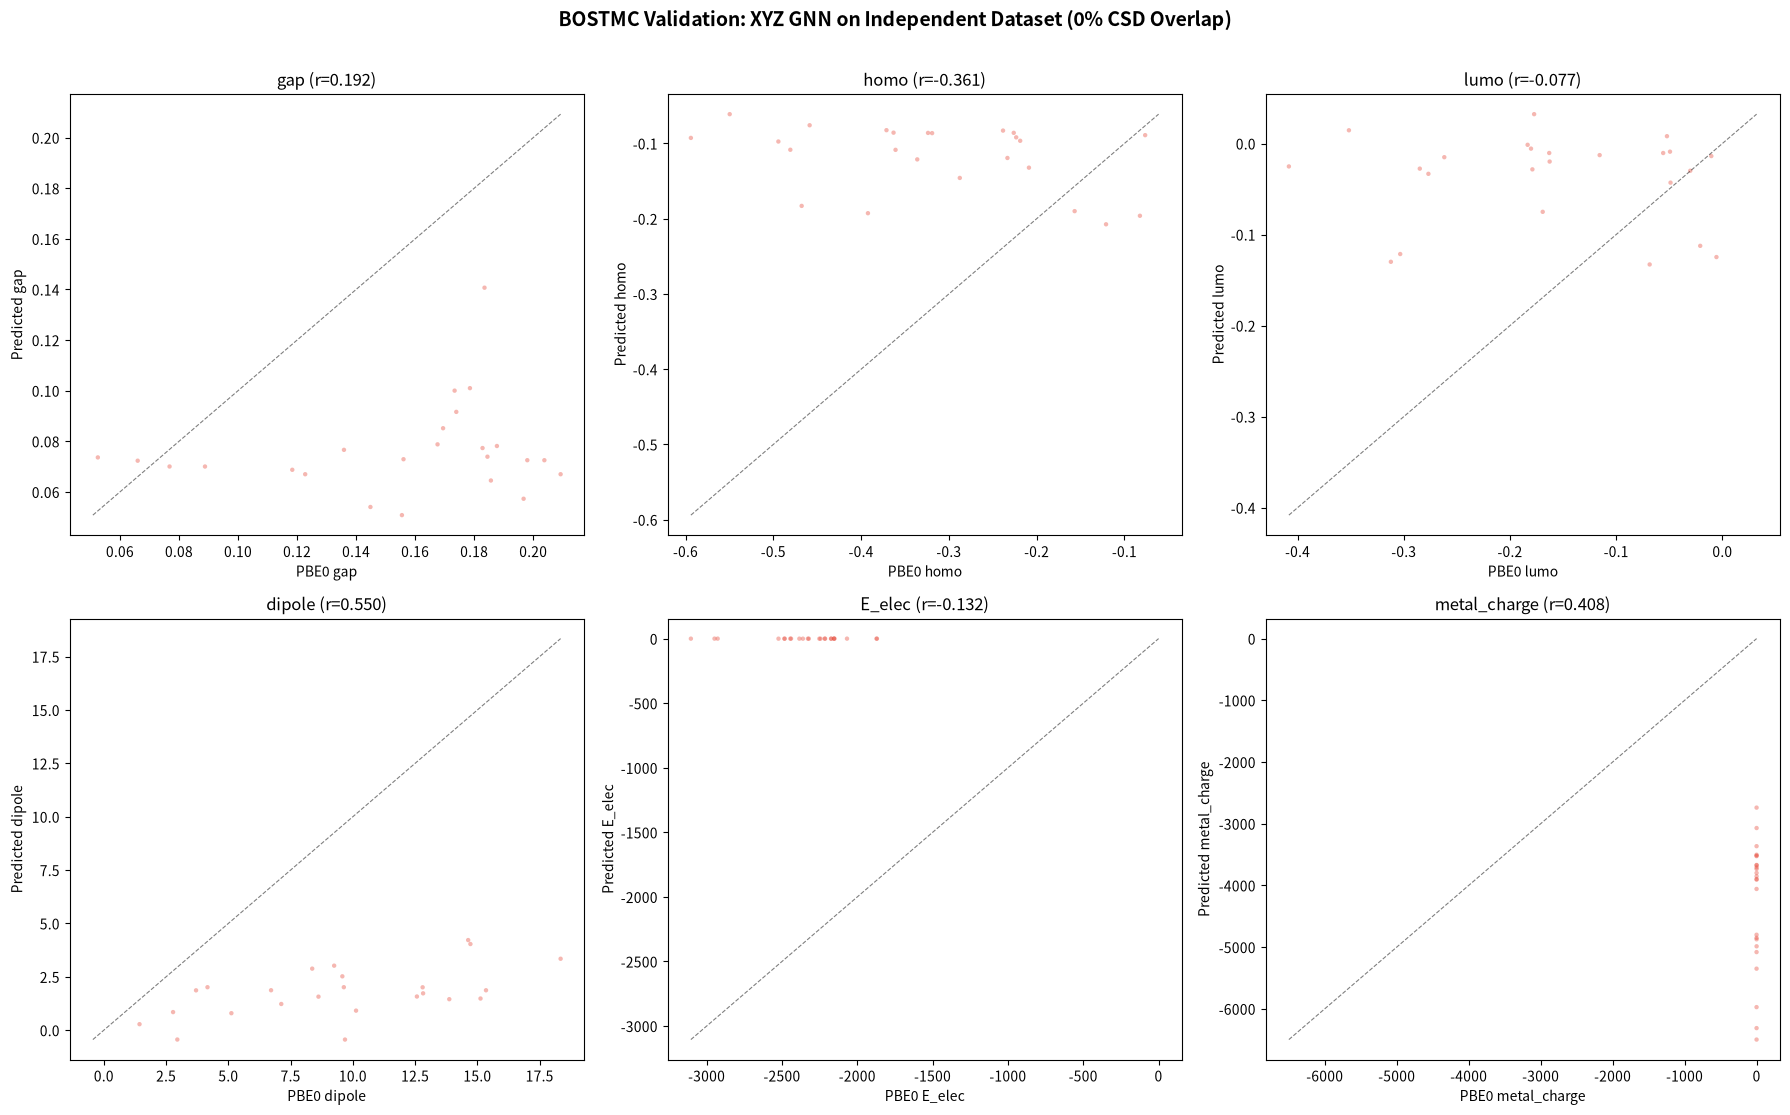

In [5]:
print('='*60)
print('Step 2: XYZ GNN Inference on BOSTMC (distance graph)')
print('='*60)

if len(graphs) == 0:
    print('ERROR: No graphs to run inference on.')
else:
    # Load XYZ GNN checkpoint
    import torch.nn as nn

    HIDDEN = 384; N_LAYERS = 5; GAT_HEADS = 12

    class XYZ_GNN_Eval(nn.Module):
        def __init__(self):
            super().__init__()
            self.embed = nn.Linear(11, HIDDEN)
            self.convs = nn.ModuleList([GATConv(HIDDEN, HIDDEN//GAT_HEADS, 23, heads=GAT_HEADS) for _ in range(N_LAYERS)])
            self.norms = nn.ModuleList([nn.LayerNorm(HIDDEN) for _ in range(N_LAYERS)])
            self.drop = nn.Dropout(0.10)
            self.readout = nn.Sequential(
                nn.Linear(HIDDEN*3, HIDDEN), nn.ReLU(), nn.Dropout(0.10),
                nn.Linear(HIDDEN, HIDDEN//2), nn.ReLU(), nn.Dropout(0.10),
                nn.Linear(HIDDEN//2, 8))
        def forward(self, g, batch=None):
            x, ei, ea = g['x'], g['edge_index'], g.get('edge_attr', None)
            h = self.embed(x)
            for conv, norm in zip(self.convs, self.norms): h = norm(h + conv(h, ei, ea)); h = self.drop(h)
            if batch is None:
                mm = (x[:,7] > 0.5); mf = h[mm].mean(dim=0) if mm.any() else torch.zeros(h.size(1), device=h.device, dtype=h.dtype)
                return self.readout(torch.cat([h.mean(0), h.max(0).values, mf])).unsqueeze(0)
            n_graphs = int(batch.max().item()) + 1
            mean_h = scatter_mean_per_graph(h, batch, n_graphs); max_h = scatter_max_per_graph(h, batch, n_graphs)
            mm = (x[:,7] > 0.5)
            mf = scatter_mean_per_graph(h[mm], batch[mm], n_graphs) if mm.any() else torch.zeros(n_graphs, h.size(1), device=h.device, dtype=h.dtype)
            return self.readout(torch.cat([mean_h, max_h, mf], dim=1))

    model = XYZ_GNN_Eval().to(device)
    ckpt = 'xyz_best.pt'
    if os.path.exists(ckpt):
        state = torch.load(ckpt, map_location=device)
        model.load_state_dict(state, strict=False)
        print(f'Loaded {ckpt}')
    else:
        print(f'{ckpt} not found!')
        exit(1)
    model.eval()

    bs = 32
    y_mean = np.array([0.108504, -0.197593, -0.089089, 5.799450, 0.162882, -2987.303526, -0.142228, 397.124993], dtype=np.float32)
    y_std  = np.array([0.033575, 0.053825, 0.054517, 3.927489, 0.782914, 1634.083288, 0.070115, 152.460083], dtype=np.float32)

    preds_list = []
    with torch.no_grad():
        for s in tqdm(range(0, len(graphs), bs), desc='XYZ GNN'):
            bg = [{k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in g.items()} for g in graphs[s:s+bs]]
            batched, batch_idx = collate_graphs(bg)
            pn = model(batched, batch_idx).cpu().numpy()
            preds_list.append(pn * y_std + y_mean)
    preds_all = np.concatenate(preds_list, axis=0)

    target_idx = [0, 1, 2, 3, 4, 5]

    print(f"\n{'='*80}")
    print(f"BOSTMC VALIDATION (N={len(graphs)}, XYZ->distance graph, 0% CSD overlap)")
    print(f"{'='*80}")
    print(f"{'Property':16s} {'Pearson r':>10s} {'MAE':>12s} {'R2':>10s}")
    print('-' * 52)

    results = []
    for j, prop in enumerate(targets_ext):
        yt = y_true[:, j]
        yp = preds_all[:, target_idx[j]]
        r_val, _ = pearsonr(yt, yp)
        mae_val = mean_absolute_error(yt, yp)
        r2_val = r2_score(yt, yp)
        print(f'{prop:16s} {r_val:10.4f} {mae_val:12.4f} {r2_val:10.4f}')
        results.append({'Property': prop, 'Pearson_r': r_val, 'MAE': mae_val, 'R2': r2_val})

    res_df = pd.DataFrame(results)
    mean_r = res_df['Pearson_r'].mean()
    print(f'\nMean Pearson r: {mean_r:.4f}')
    res_df.to_csv('bostmc_validation_results.csv', index=False)
    print('Saved to bostmc_validation_results.csv')

    import matplotlib.pyplot as plt
    plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC', 'DejaVu Sans']
    plt.rcParams['axes.unicode_minus'] = False

    fig, axes = plt.subplots(2, 3, figsize=(18, 11))
    axes = axes.flatten()
    for j, prop in enumerate(targets_ext):
        ax = axes[j]
        yt = y_true[:, j]
        yp = preds_all[:, target_idx[j]]
        r_val, _ = pearsonr(yt, yp)
        ax.scatter(yt, yp, alpha=0.4, s=10, c='#e74c3c', edgecolors='none')
        lims = [min(yt.min(), yp.min()), max(yt.max(), yp.max())]
        ax.plot(lims, lims, 'k--', lw=0.8, alpha=0.5)
        ax.set_xlabel(f'PBE0 {prop}')
        ax.set_ylabel(f'Predicted {prop}')
        ax.set_title(f'{prop} (r={r_val:.3f})')
    plt.suptitle('BOSTMC Validation: XYZ GNN on Independent Dataset (0% CSD Overlap)',
                 fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()

